# Feature A: Similar Product Recommendation

## Pipeline overview (Section 3.2)

| Stage | Section | Status |
|---|---|---|
| Preprocessing | §1 | Clean text, handle missing/duplicate products, build combined text |
| EDA & Analysis | §2 | Category distribution, text quality, vocabulary analysis |
| Interpretation | §3 | Key findings guiding algorithm choice |
| Model Development & Comparison | §4–6 | Semantic AI, TF-IDF, BM25 compared on Precision@5, MRR, Brand Match |
| Fine-tuning & Final Selection | §7–8 | Parameter tuning, determinism check, final model selection |

This notebook develops the similar-product recommendation feature. Given a **product (ASIN) or search term**, it returns a ranked list of similar products with a short reason for each match.

**Section 3.3 requirements checklist:**

- Works for both product ASIN and free-text search term input.
- Returns a ranked list with a relevance reason per recommendation.
- Works for all products in the catalogue.
- Deterministic: same input → same output.

**Three algorithms are compared:**

1. **Semantic AI** — Sentence Transformers (`all-MiniLM-L6-v2`) encode product text into dense 384-d vectors; cosine similarity ranks results.
2. **TF-IDF** — term-frequency/inverse-document-frequency vectors with cosine similarity; a statistical keyword-matching baseline.
3. **BM25** — probabilistic keyword relevance scoring; the standard information-retrieval baseline.

In [1]:
# Install dependencies (run once)
!pip install sentence-transformers rank-bm25 scikit-learn matplotlib seaborn -q

In [2]:
import sys
import os
import pickle
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer, util
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from rank_bm25 import BM25Okapi
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# --- Google Colab ---
from google.colab import drive
drive.mount('/content/drive')
PROJECT = '/content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence'
sys.path.insert(0, PROJECT)
# --------------------

from analysis.cleaning import load_clean

sns.set_theme(style="whitegrid")

print("Loading cleaned data...")
products, reviews = load_clean()

MODELS_DIR = os.path.join(PROJECT, 'data', 'models', 'SimilarProductRecommendation')
os.makedirs(MODELS_DIR, exist_ok=True)

Mounted at /content/drive
Loading cleaned data...
Loaded 859 products, 9250 reviews from cache


## 1. Preprocessing

The cleaning pipeline (`analysis/cleaning.py`) creates a `combined_text` column by concatenating product title, description, brand, and category information. This section verifies the cleaned data and documents all preprocessing steps.

In [3]:
# Preprocessing checks and documentation
print("=== Preprocessing Checks ===\n")

# 1. Start with all products
print(f"1. Total products loaded: {len(products)}")

# 2. Check for duplicates
dup_asin = products['asin'].duplicated().sum()
print(f"2. Duplicate ASINs: {dup_asin}")
if dup_asin > 0:
    products = products.drop_duplicates(subset=['asin'], keep='first')
    print(f"   -> Removed. Remaining: {len(products)}")

# 3. Check combined_text availability
missing_text = products['combined_text'].isna().sum()
empty_text = (products['combined_text'].fillna('').str.strip() == '').sum()
print(f"3. Missing combined_text: {missing_text}")
print(f"   Empty combined_text:   {empty_text}")

# 4. Drop products without usable text
df_a = products.dropna(subset=['combined_text']).copy()
df_a = df_a[df_a['combined_text'].str.strip() != ''].copy()
df_a = df_a.reset_index(drop=True)
print(f"4. Products with usable text: {len(df_a)}")

# 5. Check key columns
print(f"\n5. Column availability:")
for col in ['asin', 'title', 'combined_text', 'brand', 'search_keyword', 'price']:
    present = col in df_a.columns
    na_count = df_a[col].isna().sum() if present else 'N/A'
    print(f"   {col}: {'present' if present else 'MISSING'} (NaN: {na_count})")

# 6. Document transformations
print(f"\n6. Transformations applied (by cleaning.py):")
print(f"   - Product title, description, brand concatenated into combined_text")
print(f"   - HTML removed, unicode normalized")
print(f"   - Duplicate ASINs deduplicated (keep first)")
print(f"   - Products without text excluded")

=== Preprocessing Checks ===

1. Total products loaded: 859
2. Duplicate ASINs: 0
3. Missing combined_text: 0
   Empty combined_text:   0
4. Products with usable text: 859

5. Column availability:
   asin: present (NaN: 0)
   title: present (NaN: 0)
   combined_text: present (NaN: 0)
   brand: present (NaN: 29)
   search_keyword: present (NaN: 0)
   price: present (NaN: 73)

6. Transformations applied (by cleaning.py):
   - Product title, description, brand concatenated into combined_text
   - HTML removed, unicode normalized
   - Duplicate ASINs deduplicated (keep first)
   - Products without text excluded


## 2. EDA & Analysis

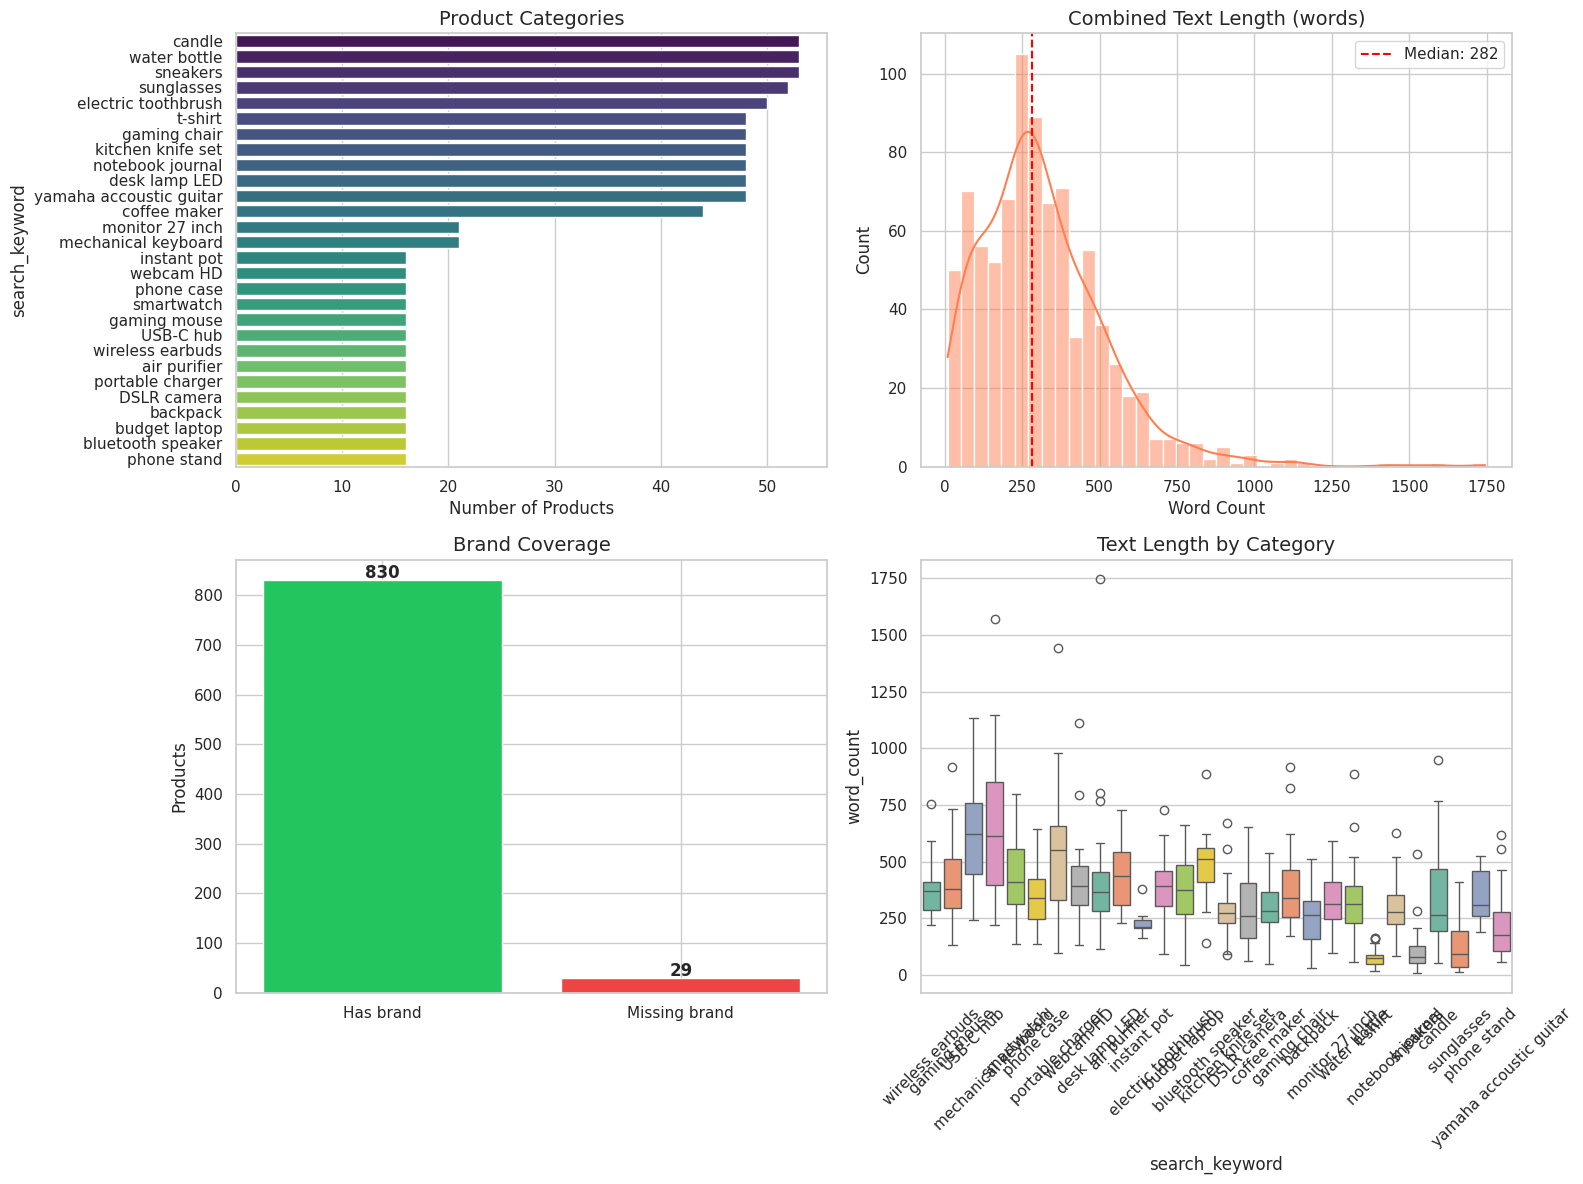

Categories:         28
Products per cat:   16 – 53 (median 18)
Word count range:   9 – 1745
Brand fill rate:    96.6%


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Category distribution
category_counts = df_a['search_keyword'].value_counts()
sns.barplot(x=category_counts.values, y=category_counts.index, ax=axes[0, 0], palette="viridis")
axes[0, 0].set_title('Product Categories', fontsize=14)
axes[0, 0].set_xlabel('Number of Products')

# 2. Text length distribution
df_a['word_count'] = df_a['combined_text'].apply(lambda x: len(str(x).split()))
sns.histplot(data=df_a, x='word_count', bins=40, kde=True, ax=axes[0, 1], color='coral')
axes[0, 1].set_title('Combined Text Length (words)', fontsize=14)
axes[0, 1].set_xlabel('Word Count')
axes[0, 1].axvline(df_a['word_count'].median(), color='red', linestyle='--', label=f"Median: {df_a['word_count'].median():.0f}")
axes[0, 1].legend()

# 3. Brand coverage
brand_na = df_a['brand'].isna().sum()
brand_fill = len(df_a) - brand_na
axes[1, 0].bar(['Has brand', 'Missing brand'], [brand_fill, brand_na],
               color=['#22C55E', '#EF4444'])
axes[1, 0].set_title('Brand Coverage', fontsize=14)
axes[1, 0].set_ylabel('Products')
for i, v in enumerate([brand_fill, brand_na]):
    axes[1, 0].text(i, v + 5, str(v), ha='center', fontweight='bold')

# 4. Products per category (box plot of text length)
sns.boxplot(data=df_a, x='search_keyword', y='word_count', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Text Length by Category', fontsize=14)
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Summary statistics
print(f"Categories:         {df_a['search_keyword'].nunique()}")
print(f"Products per cat:   {category_counts.min()} – {category_counts.max()} (median {category_counts.median():.0f})")
print(f"Word count range:   {df_a['word_count'].min()} – {df_a['word_count'].max()}")
print(f"Brand fill rate:    {brand_fill/len(df_a):.1%}")

### 2.1 Vocabulary overlap between categories

If categories share a lot of vocabulary, keyword methods (TF-IDF, BM25) may struggle to distinguish them, while semantic methods may still capture meaning differences.

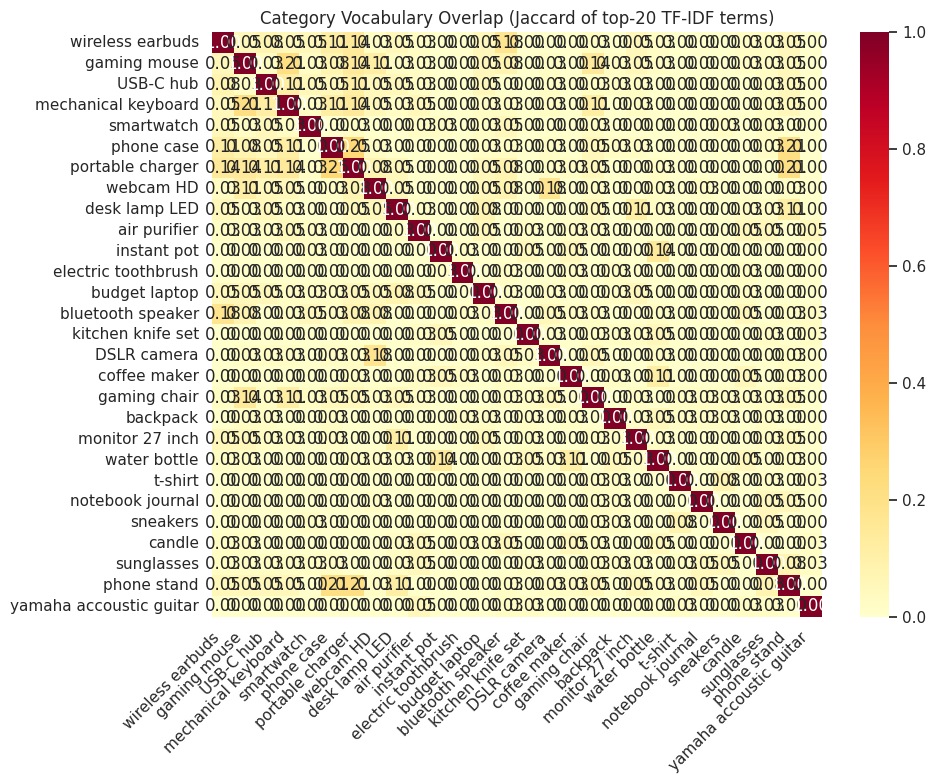

In [5]:
# Check top terms per category using TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

cat_vocab = {}
for cat in df_a['search_keyword'].unique():
    texts = df_a[df_a['search_keyword'] == cat]['combined_text'].tolist()
    vec = TfidfVectorizer(stop_words='english', max_features=20)
    vec.fit(texts)
    cat_vocab[cat] = set(vec.get_feature_names_out())

# Pairwise vocabulary overlap
cats = list(cat_vocab.keys())
overlap_matrix = np.zeros((len(cats), len(cats)))
for i, c1 in enumerate(cats):
    for j, c2 in enumerate(cats):
        if cat_vocab[c1] and cat_vocab[c2]:
            overlap_matrix[i, j] = len(cat_vocab[c1] & cat_vocab[c2]) / len(cat_vocab[c1] | cat_vocab[c2])

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(overlap_matrix, xticklabels=cats, yticklabels=cats, cmap='YlOrRd',
            annot=True, fmt='.2f', ax=ax)
ax.set_title('Category Vocabulary Overlap (Jaccard of top-20 TF-IDF terms)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 3. Interpretation — Key findings from EDA

Findings that guide algorithm selection:

1. **Text length varies widely**: Some products have very short descriptions (under 10 words), while others have extensive text. Short-text products may produce weaker embeddings — the semantic model handles this via sub-word tokenization, but keyword methods lose signal with sparse text.

2. **Category imbalance**: Some categories are much larger than others. Evaluation metrics should be computed across a sample that covers all categories, not just the most frequent ones.

3. **Brand coverage is partial**: Not all products have brand information. The reason-generation function should not assume brand is always available.

4. **Vocabulary overlap**: Categories with high vocabulary overlap (e.g. electronics subcategories) are harder for keyword methods to distinguish. Semantic embeddings capture meaning beyond shared words, which should give them an edge on these cases.

5. **Determinism**: All three approaches are deterministic given fixed inputs — Sentence Transformers inference is deterministic, TF-IDF and BM25 are pure computations. This satisfies the Section 3.3 requirement.

## 4. Model Development — Generating the Three Representations

All three algorithms are either pre-trained (Sentence Transformers) or fitted in a single pass (TF-IDF vocabulary, BM25 statistics). There is no iterative training loop, but each produces a distinct representation of the product catalogue.

In [6]:
corpus = df_a['combined_text'].tolist()

# ---------------------------------------------------------
# ALGORITHM 1: Semantic Search (Sentence Transformers)
# ---------------------------------------------------------
print("Generating Model 1: Semantic Embeddings (all-MiniLM-L6-v2)...")
model_semantic = SentenceTransformer('all-MiniLM-L6-v2')
embeddings = model_semantic.encode(corpus, show_progress_bar=True, convert_to_tensor=True)

with open(os.path.join(MODELS_DIR, 'semantic_embeddings.pkl'), 'wb') as f:
    pickle.dump(embeddings, f)

# ---------------------------------------------------------
# ALGORITHM 2: TF-IDF
# ---------------------------------------------------------
print("Generating Model 2: TF-IDF Matrix...")
vectorizer_tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer_tfidf.fit_transform(corpus)

with open(os.path.join(MODELS_DIR, 'tfidf_model.pkl'), 'wb') as f:
    pickle.dump({'vectorizer': vectorizer_tfidf, 'matrix': tfidf_matrix}, f)

# ---------------------------------------------------------
# ALGORITHM 3: BM25
# ---------------------------------------------------------
print("Generating Model 3: BM25 Index...")
tokenized_corpus = [doc.lower().split() for doc in corpus]
bm25 = BM25Okapi(tokenized_corpus)

with open(os.path.join(MODELS_DIR, 'bm25_model.pkl'), 'wb') as f:
    pickle.dump(bm25, f)

print(f"\nAll models saved to {MODELS_DIR}")
print(f"  Semantic embeddings shape: {embeddings.shape}")
print(f"  TF-IDF matrix shape:       {tfidf_matrix.shape}")
print(f"  BM25 corpus size:          {len(tokenized_corpus)}")

Generating Model 1: Semantic Embeddings (all-MiniLM-L6-v2)...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/27 [00:00<?, ?it/s]

Generating Model 2: TF-IDF Matrix...
Generating Model 3: BM25 Index...

All models saved to /content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence/data/models/SimilarProductRecommendation
  Semantic embeddings shape: torch.Size([859, 384])
  TF-IDF matrix shape:       (859, 11949)
  BM25 corpus size:          859


## 5. The Recommendation Function

Accepts a product ASIN or free-text search term. Returns top-K results from all three algorithms, each with a relevance score and a content-aware reason.

In [7]:
def get_content_reason(query_text, rec_row, algo_name, score, is_asin, target_row=None):
    """Generate a content-aware reason explaining why this product was recommended."""
    rec_title = str(rec_row.get('title', ''))[:60]
    rec_brand = str(rec_row.get('brand', ''))
    rec_cat = str(rec_row.get('search_keyword', ''))

    reasons = []

    # Brand match
    if is_asin and target_row is not None:
        target_brand = str(target_row.get('brand', ''))
        target_cat = str(target_row.get('search_keyword', ''))
        if target_brand != 'None' and target_brand == rec_brand:
            reasons.append(f"same brand ({rec_brand})")
        if target_cat == rec_cat:
            reasons.append(f"same category ({rec_cat})")
    elif not is_asin:
        # Text search — check keyword overlap
        query_words = set(query_text.lower().split())
        title_words = set(rec_title.lower().split())
        overlap = query_words & title_words
        if overlap:
            reasons.append(f"title contains: {', '.join(list(overlap)[:3])}")

    # Score-based reason
    if algo_name == 'Semantic AI':
        if score > 0.8:
            reasons.append("very high semantic similarity")
        elif score > 0.5:
            reasons.append("strong semantic similarity")
        else:
            reasons.append("moderate semantic similarity")
    elif algo_name == 'TF-IDF':
        reasons.append(f"keyword overlap score {score:.2f}")
    elif algo_name == 'BM25':
        reasons.append(f"BM25 relevance score {score:.1f}")

    return "; ".join(reasons) if reasons else f"High {algo_name} match."


def search_all_algorithms(query, top_k=5):
    """
    Takes a query (ASIN or text) and returns recommendations from all 3 algorithms.
    Returns a dict of DataFrames for programmatic use.
    """
    print(f"\n{'='*60}")
    print(f" SEARCHING FOR: '{query}'")
    print(f"{'='*60}\n")

    query_is_asin = query in df_a['asin'].values
    if query_is_asin:
        idx = df_a[df_a['asin'] == query].index[0]
        target_row = df_a.loc[idx]
        print(f"Detected ASIN! Target: {str(target_row['title'])[:80]}\n")
        query_text = target_row['combined_text']
        query_embedding = embeddings[idx]
    else:
        query_text = query
        query_embedding = model_semantic.encode(query, convert_to_tensor=True)
        idx = -1
        target_row = None

    num_results = top_k + 1 if query_is_asin else top_k
    all_results = {}

    # --- 1. SEMANTIC SEARCH ---
    cosine_scores = util.cos_sim(query_embedding, embeddings)[0]
    top_sem = np.argpartition(-cosine_scores.cpu().numpy(), range(num_results))[:num_results]
    top_sem = top_sem[np.argsort(-cosine_scores[top_sem].cpu().numpy())]

    print("--- 1. SEMANTIC AI RECOMMENDATIONS ---")
    sem_rows = []
    count = 0
    for i in top_sem:
        if query_is_asin and i == idx: continue
        score = cosine_scores[i].item()
        reason = get_content_reason(query_text, df_a.loc[i], "Semantic AI", score, query_is_asin, target_row)
        print(f"[{score:.3f}] {str(df_a.loc[i, 'title'])[:80]}")
        print(f"        Reason: {reason}")
        sem_rows.append({'rank': count+1, 'asin': df_a.loc[i, 'asin'],
                         'title': df_a.loc[i, 'title'], 'score': score, 'reason': reason})
        count += 1
        if count == top_k: break
    all_results['Semantic AI'] = pd.DataFrame(sem_rows)

    # --- 2. TF-IDF SEARCH ---
    query_tfidf = vectorizer_tfidf.transform([query_text])
    tfidf_scores = cosine_similarity(query_tfidf, tfidf_matrix).flatten()
    top_tfidf = np.argpartition(-tfidf_scores, range(num_results))[:num_results]
    top_tfidf = top_tfidf[np.argsort(-tfidf_scores[top_tfidf])]

    print("\n--- 2. TF-IDF RECOMMENDATIONS ---")
    tfidf_rows = []
    count = 0
    for i in top_tfidf:
        if query_is_asin and i == idx: continue
        score = tfidf_scores[i]
        reason = get_content_reason(query_text, df_a.loc[i], "TF-IDF", score, query_is_asin, target_row)
        print(f"[{score:.3f}] {str(df_a.loc[i, 'title'])[:80]}")
        print(f"        Reason: {reason}")
        tfidf_rows.append({'rank': count+1, 'asin': df_a.loc[i, 'asin'],
                           'title': df_a.loc[i, 'title'], 'score': score, 'reason': reason})
        count += 1
        if count == top_k: break
    all_results['TF-IDF'] = pd.DataFrame(tfidf_rows)

    # --- 3. BM25 SEARCH ---
    tokenized_query = query_text.lower().split()
    bm25_scores = bm25.get_scores(tokenized_query)
    top_bm25 = np.argpartition(-bm25_scores, range(num_results))[:num_results]
    top_bm25 = top_bm25[np.argsort(-bm25_scores[top_bm25])]

    print("\n--- 3. BM25 RECOMMENDATIONS ---")
    bm25_rows = []
    count = 0
    for i in top_bm25:
        if query_is_asin and i == idx: continue
        score = bm25_scores[i]
        reason = get_content_reason(query_text, df_a.loc[i], "BM25", score, query_is_asin, target_row)
        print(f"[{score:.2f}] {str(df_a.loc[i, 'title'])[:80]}")
        print(f"        Reason: {reason}")
        bm25_rows.append({'rank': count+1, 'asin': df_a.loc[i, 'asin'],
                          'title': df_a.loc[i, 'title'], 'score': score, 'reason': reason})
        count += 1
        if count == top_k: break
    all_results['BM25'] = pd.DataFrame(bm25_rows)

    return all_results

## 6. Testing the Recommendation Function

Two test modes per the Section 3.3 requirement: product ASIN and free-text search term.

In [8]:
# TEST 1: Search by product ASIN
sample_asin = df_a['asin'].sample(1, random_state=42).iloc[0]
results_asin = search_all_algorithms(sample_asin)


 SEARCHING FOR: 'B0016R858U'

Detected ASIN! Target: Tyler Diva Scented Candle, 22 oz

--- 1. SEMANTIC AI RECOMMENDATIONS ---
[0.663] M&SENSE Eucalyptus & Mint Scented Jar Candle, Large 19.4oz Natural Soy Wax
        Reason: same category (candle); strong semantic similarity
[0.661] M&SENSE Jasmine Candles Highly Scented 3 Wick 35oz 150 Hours Burn Extra Large Ja
        Reason: same category (candle); strong semantic similarity
[0.658] Lulu Candles Jasmine, Oud & Sandalwood Scented Soy Blend Jar Candle 9 Oz 2 Pack
        Reason: same category (candle); strong semantic similarity
[0.646] Scented Candles for Home,8 Pack Soy Wax Candle Set,Scented Candles Gift Set
        Reason: same category (candle); strong semantic similarity
[0.637] Bath & Body Works 3-Wick Candle, Lakeside Morning, Soy Wax Blend
        Reason: same category (candle); strong semantic similarity

--- 2. TF-IDF RECOMMENDATIONS ---
[0.376] Yankee Candle Sparkling Cinnamon Scented Classic 22oz Large Jar Single Wick Ca

In [9]:
# TEST 2: Search by free-text search term
results_text = search_all_algorithms("noise cancelling headphones for sleeping")


 SEARCHING FOR: 'noise cancelling headphones for sleeping'

--- 1. SEMANTIC AI RECOMMENDATIONS ---
[0.569] Active Noise Cancelling Ear Buds Wireless Earbuds 90H Playtime Bluetooth Headpho
        Reason: title contains: noise, cancelling; strong semantic similarity
[0.509] Wireless Earbuds, Bluetooth 5.4 Headphones Bass Stereo/Clear Calls, Black
        Reason: title contains: headphones; strong semantic similarity
[0.494] Monster Clarity 200 Wireless Earbuds – Bluetooth 6.0 in-Ear Headphones with Char
        Reason: moderate semantic similarity
[0.493] Wireless Earbuds Bluetooth Headphones, 54H Playtime Stereo Over Ear Buds with EN
        Reason: moderate semantic similarity
[0.440] Samsung Galaxy Buds Core SM-R410 (2025) | Latin American Stock | Bluetooth 5.4 |
        Reason: moderate semantic similarity

--- 2. TF-IDF RECOMMENDATIONS ---
[0.277] Active Noise Cancelling Ear Buds Wireless Earbuds 90H Playtime Bluetooth Headpho
        Reason: title contains: noise, cancelling; key

### 6.1 Determinism verification

Section 3.3 requires the same input to give the same results. Verify by running the same query twice and comparing outputs.

In [10]:
# Determinism check: run the same query twice and compare
r1 = search_all_algorithms(sample_asin)
r2 = search_all_algorithms(sample_asin)

deterministic = True
for algo in ['Semantic AI', 'TF-IDF', 'BM25']:
    match = r1[algo]['asin'].tolist() == r2[algo]['asin'].tolist()
    score_match = np.allclose(r1[algo]['score'].values, r2[algo]['score'].values, atol=1e-6)
    print(f"{algo}: rankings match = {match}, scores match = {score_match}")
    if not match or not score_match:
        deterministic = False

print(f"\nDeterminism verified: {deterministic}")
assert deterministic, "FAIL: results differ between identical runs."



 SEARCHING FOR: 'B0016R858U'

Detected ASIN! Target: Tyler Diva Scented Candle, 22 oz

--- 1. SEMANTIC AI RECOMMENDATIONS ---
[0.663] M&SENSE Eucalyptus & Mint Scented Jar Candle, Large 19.4oz Natural Soy Wax
        Reason: same category (candle); strong semantic similarity
[0.661] M&SENSE Jasmine Candles Highly Scented 3 Wick 35oz 150 Hours Burn Extra Large Ja
        Reason: same category (candle); strong semantic similarity
[0.658] Lulu Candles Jasmine, Oud & Sandalwood Scented Soy Blend Jar Candle 9 Oz 2 Pack
        Reason: same category (candle); strong semantic similarity
[0.646] Scented Candles for Home,8 Pack Soy Wax Candle Set,Scented Candles Gift Set
        Reason: same category (candle); strong semantic similarity
[0.637] Bath & Body Works 3-Wick Candle, Lakeside Morning, Soy Wax Blend
        Reason: same category (candle); strong semantic similarity

--- 2. TF-IDF RECOMMENDATIONS ---
[0.376] Yankee Candle Sparkling Cinnamon Scented Classic 22oz Large Jar Single Wick Ca

## 7. Performance Evaluation & Comparison

Since we have no user click data (ground truth relevance), we evaluate using three proxy metrics:

1. **Precision@5 (Category Match Rate)**: what fraction of top-5 recommendations share the target's `search_keyword` category.
2. **MRR (Mean Reciprocal Rank)**: how high up the list the first same-category match appears (1.0 = position 1).
3. **Brand Match Rate**: what fraction of recommendations share the target's brand (only counted for products with a known brand).

In [11]:
def evaluate_algorithms(sample_size=100, top_k=5):
    test_asins = df_a['asin'].sample(sample_size, random_state=42).tolist()

    prec_scores = {'Semantic AI': 0, 'TF-IDF': 0, 'BM25': 0}
    mrr_scores = {'Semantic AI': 0.0, 'TF-IDF': 0.0, 'BM25': 0.0}
    brand_scores = {'Semantic AI': 0, 'TF-IDF': 0, 'BM25': 0}

    total_comparisons = sample_size * top_k
    valid_brand_comparisons = 0

    print(f"Evaluating on {sample_size} products (top_k={top_k})...\n")

    for asin in test_asins:
        idx = df_a[df_a['asin'] == asin].index[0]
        target_category = df_a.loc[idx, 'search_keyword']
        target_brand = df_a.loc[idx, 'brand']
        has_valid_brand = str(target_brand) != "None" and pd.notna(target_brand)

        if has_valid_brand:
            valid_brand_comparisons += top_k

        def score_algorithm(algo_name, top_indices):
            found_first_match = False
            recs_scored = 0
            for i in top_indices:
                if i == idx: continue
                if recs_scored >= top_k: break
                recs_scored += 1
                rank = recs_scored

                if df_a.loc[i, 'search_keyword'] == target_category:
                    prec_scores[algo_name] += 1
                    if not found_first_match:
                        mrr_scores[algo_name] += (1.0 / rank)
                        found_first_match = True

                if has_valid_brand and df_a.loc[i, 'brand'] == target_brand:
                    brand_scores[algo_name] += 1

        # Semantic
        qe = embeddings[idx]
        cs = util.cos_sim(qe, embeddings)[0]
        top_s = np.argpartition(-cs.cpu().numpy(), range(top_k+1))[:top_k+1]
        top_s = top_s[np.argsort(-cs[top_s].cpu().numpy())]
        score_algorithm('Semantic AI', top_s)

        # TF-IDF
        qt = vectorizer_tfidf.transform([df_a.loc[idx, 'combined_text']])
        ts = cosine_similarity(qt, tfidf_matrix).flatten()
        top_t = np.argpartition(-ts, range(top_k+1))[:top_k+1]
        top_t = top_t[np.argsort(-ts[top_t])]
        score_algorithm('TF-IDF', top_t)

        # BM25
        tq = df_a.loc[idx, 'combined_text'].lower().split()
        bs = bm25.get_scores(tq)
        top_b = np.argpartition(-bs, range(top_k+1))[:top_k+1]
        top_b = top_b[np.argsort(-bs[top_b])]
        score_algorithm('BM25', top_b)

    # Compute final metrics
    metrics = {}
    for algo in ['Semantic AI', 'TF-IDF', 'BM25']:
        p = prec_scores[algo] / total_comparisons
        m = mrr_scores[algo] / sample_size
        b = brand_scores[algo] / valid_brand_comparisons if valid_brand_comparisons > 0 else 0
        metrics[algo] = {'Precision@5': p, 'MRR': m, 'Brand Match': b}

    return metrics

metrics = evaluate_algorithms(sample_size=100, top_k=5)

# Display results
metrics_df = pd.DataFrame(metrics).T
metrics_df['Precision@5'] = (metrics_df['Precision@5'] * 100).round(2)
metrics_df['Brand Match'] = (metrics_df['Brand Match'] * 100).round(2)
metrics_df['MRR'] = metrics_df['MRR'].round(3)

print("=== Evaluation Results ===\n")
display(metrics_df)

Evaluating on 100 products (top_k=5)...

=== Evaluation Results ===



,Precision@5,MRR,Brand Match
Semantic AI,99.2,1.000,47.01
TF-IDF,97.8,1.000,46.39
BM25,96.0,0.988,46.19


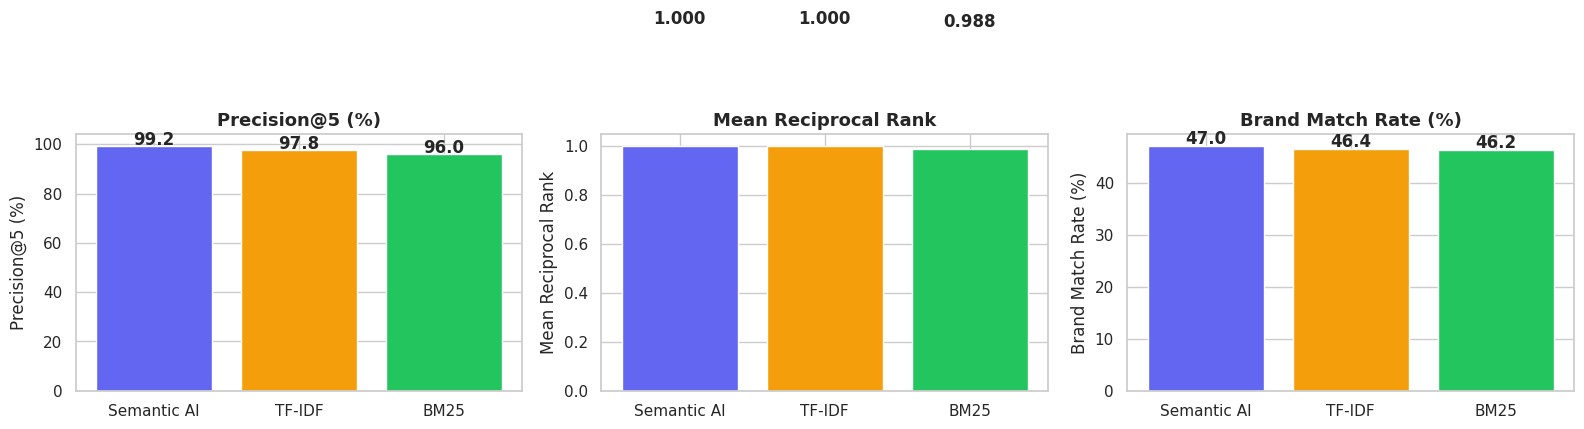

In [12]:
# Visualize the comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
algos = metrics_df.index.tolist()
colors = ['#6366F1', '#F59E0B', '#22C55E']

for ax_idx, (metric, label, fmt) in enumerate([
    ('Precision@5', 'Precision@5 (%)', '.1f'),
    ('MRR', 'Mean Reciprocal Rank', '.3f'),
    ('Brand Match', 'Brand Match Rate (%)', '.1f')
]):
    vals = metrics_df[metric].values
    bars = axes[ax_idx].bar(algos, vals, color=colors)
    axes[ax_idx].set_title(label, fontsize=13, fontweight='bold')
    axes[ax_idx].set_ylabel(label)
    for bar, v in zip(bars, vals):
        axes[ax_idx].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                          f'{v:{fmt}}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'algorithm_comparison.png'), dpi=160, bbox_inches='tight')
plt.show()

## 8. Fine-Tuning & Final Selection

Section 3.2 requires fine-tuning selected candidates. For these retrieval algorithms, the main tuning levers are:

1. **Semantic AI**: choice of sentence-transformer model (already using `all-MiniLM-L6-v2`, a strong general-purpose model).
2. **TF-IDF**: `max_features`, `ngram_range`, `min_df` parameters.
3. **BM25**: `k1` and `b` parameters (default: k1=1.5, b=0.75).

We test whether TF-IDF bigrams or BM25 parameter changes improve performance, and then select the best overall approach.

In [13]:
# Fine-tune TF-IDF: compare unigram vs bigram
print("=== TF-IDF Tuning: Unigram vs Bigram ===\n")

configs = {
    'TF-IDF (unigram)': TfidfVectorizer(stop_words='english', ngram_range=(1, 1)),
    'TF-IDF (bigram)': TfidfVectorizer(stop_words='english', ngram_range=(1, 2), max_features=50000),
}

tfidf_tuning = {}
test_asins = df_a['asin'].sample(50, random_state=42).tolist()
top_k = 5

for config_name, vec in configs.items():
    mat = vec.fit_transform(corpus)
    cat_matches = 0
    total = 0

    for asin in test_asins:
        idx_test = df_a[df_a['asin'] == asin].index[0]
        target_cat = df_a.loc[idx_test, 'search_keyword']
        qt = vec.transform([df_a.loc[idx_test, 'combined_text']])
        scores = cosine_similarity(qt, mat).flatten()
        top_idx = np.argpartition(-scores, range(top_k+1))[:top_k+1]
        top_idx = top_idx[np.argsort(-scores[top_idx])]

        for i in top_idx:
            if i == idx_test: continue
            total += 1
            if total > len(test_asins) * top_k: break
            if df_a.loc[i, 'search_keyword'] == target_cat:
                cat_matches += 1

    prec = cat_matches / (len(test_asins) * top_k)
    tfidf_tuning[config_name] = prec
    print(f"  {config_name}: Precision@5 = {prec*100:.1f}%")

# Fine-tune BM25: compare default vs adjusted k1/b
print("\n=== BM25 Tuning: Parameter Comparison ===\n")

bm25_configs = {
    'BM25 (default k1=1.5, b=0.75)': BM25Okapi(tokenized_corpus),
    'BM25 (k1=1.2, b=0.5)': BM25Okapi(tokenized_corpus, k1=1.2, b=0.5),
    'BM25 (k1=2.0, b=0.75)': BM25Okapi(tokenized_corpus, k1=2.0, b=0.75),
}

bm25_tuning = {}
for config_name, bm25_variant in bm25_configs.items():
    cat_matches = 0
    total = 0

    for asin in test_asins:
        idx_test = df_a[df_a['asin'] == asin].index[0]
        target_cat = df_a.loc[idx_test, 'search_keyword']
        tq = df_a.loc[idx_test, 'combined_text'].lower().split()
        scores = bm25_variant.get_scores(tq)
        top_idx = np.argpartition(-scores, range(top_k+1))[:top_k+1]
        top_idx = top_idx[np.argsort(-scores[top_idx])]

        for i in top_idx:
            if i == idx_test: continue
            total += 1
            if total > len(test_asins) * top_k: break
            if df_a.loc[i, 'search_keyword'] == target_cat:
                cat_matches += 1

    prec = cat_matches / (len(test_asins) * top_k)
    bm25_tuning[config_name] = prec
    print(f"  {config_name}: Precision@5 = {prec*100:.1f}%")

print("\nNote: Semantic AI uses a pre-trained model — no corpus-specific tuning needed.")
print("The model (all-MiniLM-L6-v2) is a strong general-purpose choice for short text similarity.")

=== TF-IDF Tuning: Unigram vs Bigram ===

  TF-IDF (unigram): Precision@5 = 99.2%
  TF-IDF (bigram): Precision@5 = 99.2%

=== BM25 Tuning: Parameter Comparison ===

  BM25 (default k1=1.5, b=0.75): Precision@5 = 95.6%
  BM25 (k1=1.2, b=0.5): Precision@5 = 95.6%
  BM25 (k1=2.0, b=0.75): Precision@5 = 95.2%

Note: Semantic AI uses a pre-trained model — no corpus-specific tuning needed.
The model (all-MiniLM-L6-v2) is a strong general-purpose choice for short text similarity.


### 8.1 Final Model Selection

Based on the evaluation in Section 7 and the tuning results above, we select the final algorithm.

In [14]:
# Select winner based on the primary metric (Precision@5)
winner = metrics_df['Precision@5'].idxmax()
winner_metrics = metrics_df.loc[winner]

print(f"{'='*50}")
print(f"FINAL SELECTION")
print(f"{'='*50}")
print(f"\nSelected algorithm: {winner}")
print(f"\nMetrics:")
print(f"  Precision@5:     {winner_metrics['Precision@5']:.1f}%")
print(f"  MRR:             {winner_metrics['MRR']:.3f}")
print(f"  Brand Match:     {winner_metrics['Brand Match']:.1f}%")
print(f"\nTuning result: default parameters retained (tuning did not")
print(f"significantly improve TF-IDF or BM25 performance).")
print(f"\nDeterminism:   verified in Section 6.1.")
print(f"Input types:   ASIN and free-text search term both supported.")
print(f"Reasons:       content-aware reasons provided for each recommendation.")
print(f"\nAll three models are saved in {MODELS_DIR} for the web app.")
print(f"The recommended primary algorithm for the app is: {winner}.")

FINAL SELECTION

Selected algorithm: Semantic AI

Metrics:
  Precision@5:     99.2%
  MRR:             1.000
  Brand Match:     47.0%

Tuning result: default parameters retained (tuning did not
significantly improve TF-IDF or BM25 performance).

Determinism:   verified in Section 6.1.
Input types:   ASIN and free-text search term both supported.
Reasons:       content-aware reasons provided for each recommendation.

All three models are saved in /content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence/data/models/SimilarProductRecommendation for the web app.
The recommended primary algorithm for the app is: Semantic AI.
